# Ordinal Encoding on the Used-Car Dataset

This notebook explores ordinal encoding using `cars.csv`. It loads the data independently, inspects its real columns, encodes the same three categorical features used in the companion one-hot notebook, and visualizes the categories, prices, dimensionality, and encoded-feature correlations.

**Important:** ordinal codes represent order. `owner` has a meaningful order for the count of previous owners. `brand` and `fuel` are nominal; their alphabetical codes are only deterministic labels, not a meaningful ranking. “Test Drive Car” is a special status rather than an owner-count rank, so this notebook assigns it a separate sentinel code.

Run the cells from top to bottom. The CSV should be beside this notebook, as in the supplied `feature-engineering/encoding` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Support both running from the notebook's folder and from a project root.
search_roots = [Path.cwd(), *Path.cwd().parents]
candidates = [root / "cars.csv" for root in search_roots]
candidates += [root / "feature-engineering" / "encoding" / "cars.csv" for root in search_roots]
DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find cars.csv. Place it beside this notebook or run from the project tree.")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded /Users/srinivasaraotadela/Documents/ml/feature-engineering/encoding/cars.csv
Shape: 8,128 rows × 5 columns


,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


## 1. Inspect the real dataset

First check column types, missingness, and summary statistics before choosing an encoding. In this file, `selling_price` is the numeric outcome to analyze, not an input feature to encode. We encode `brand`, `fuel`, and `owner`; `km_driven` is already numeric.

In [2]:
print("Column names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nSummary statistics (all columns):")
display(df.describe(include="all").T)

categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
expected_categorical_columns = ["brand", "fuel", "owner"]
if categorical_columns != expected_categorical_columns:
    raise ValueError(f"Expected categorical columns {expected_categorical_columns}, found {categorical_columns}")
target_column = "selling_price"
numeric_predictors = [column for column in df.select_dtypes(include="number").columns if column != target_column]
print("\nCategorical columns used in both notebooks:", categorical_columns)
print("Numeric predictor kept unchanged:", numeric_predictors)
for column in categorical_columns:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())

Column names: ['brand', 'km_driven', 'fuel', 'owner', 'selling_price']

Data types:
 brand            object
km_driven         int64
fuel             object
owner            object
selling_price     int64
dtype: object

Missing values:
 brand            0
km_driven        0
fuel             0
owner            0
selling_price    0
dtype: int64

Summary statistics (all columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,8128,32,Maruti,2448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
km_driven,"8,128.00",NaN,NaN,NaN,"69,819.51","56,550.55",1.00,"35,000.00","60,000.00","98,000.00","2,360,457.00"
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
selling_price,"8,128.00",NaN,NaN,NaN,"638,271.81","806,253.40","29,999.00","254,999.00","450,000.00","675,000.00","10,000,000.00"



Categorical columns used in both notebooks: ['brand', 'fuel', 'owner']
Numeric predictor kept unchanged: ['km_driven']

brand: 32 categories


,count
brand,
Maruti,2448
Hyundai,1415
Mahindra,772
Tata,734
Toyota,488
Honda,467
Ford,397
Chevrolet,230
Renault,228



fuel: 4 categories


,count
fuel,
Diesel,4402
Petrol,3631
CNG,57
LPG,38



owner: 5 categories


,count
owner,
First Owner,5289
Second Owner,2105
Third Owner,555
Fourth & Above Owner,174
Test Drive Car,5


## 2. Choose an encoding and handle special values

`brand` and `fuel` have no natural ranking. We give their observed categories alphabetical integer codes only to make the transformation reproducible; those codes must **not** be interpreted as brand or fuel importance. For owner count, the natural sequence is First → Second → Third → Fourth & Above, representing increasing previous-owner count.

“Test Drive Car” does not belong on that owner-count scale. We retain the row and map that status to a dedicated sentinel, then set its output to `-1`. Actual missing values receive `-3`, while categories not known by the fitted encoder receive `-2`. This keeps the three cases distinct instead of inventing an owner-count rank. The supplied dataset currently has no missing values, but the encoder is configured for them.

This notebook fits on all rows to demonstrate encoding for analysis, not to estimate model performance. In a predictive workflow, fit preprocessing on training data only—ideally inside a scikit-learn pipeline.

In [3]:
category_levels = {
    column: sorted(df[column].dropna().unique().tolist())
    for column in categorical_columns
}
owner_order = ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]
special_owner_status = "Test Drive Car"
if set(df["owner"].dropna().unique()) != set(owner_order + [special_owner_status]):
    raise ValueError("The observed owner labels differ from the order documented for this dataset.")

MISSING_CATEGORY = "__MISSING__"
TEST_DRIVE_CATEGORY = "__TEST_DRIVE__"
if any(label in levels for levels in category_levels.values() for label in [MISSING_CATEGORY, TEST_DRIVE_CATEGORY]):
    raise ValueError("A reserved sentinel already appears among the observed categories.")

def prepare_ordinal_input(frame):
    """Replace nulls and the unranked owner status with explicit string sentinels."""
    prepared = frame[categorical_columns].copy().astype(object)
    missing_mask = prepared.isna()
    test_drive_mask = prepared["owner"].eq(special_owner_status)
    prepared = prepared.where(~missing_mask, MISSING_CATEGORY)
    prepared["owner"] = prepared["owner"].replace(special_owner_status, TEST_DRIVE_CATEGORY)
    return prepared, missing_mask, test_drive_mask

encoder_input, missing_mask, test_drive_mask = prepare_ordinal_input(df)

ordinal_encoder = OrdinalEncoder(
    categories=[
        category_levels["brand"] + [MISSING_CATEGORY],
        category_levels["fuel"] + [MISSING_CATEGORY],
        owner_order + [TEST_DRIVE_CATEGORY, MISSING_CATEGORY],
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-2,
    encoded_missing_value=-3,
    dtype=np.int64,
)
encoded_array = ordinal_encoder.fit_transform(encoder_input)
encoded_array[missing_mask.to_numpy()] = -3
owner_position = categorical_columns.index("owner")
encoded_array[test_drive_mask.to_numpy(), owner_position] = -1
encoded_df = pd.DataFrame(encoded_array, columns=categorical_columns, index=df.index)

ordinal_maps = {
    column: {label: code for code, label in enumerate(levels)}
    for column, levels in zip(categorical_columns, [category_levels["brand"], category_levels["fuel"], owner_order])
}
ordinal_maps["owner"][special_owner_status] = -1
print("Mappings (brand/fuel codes are arbitrary alphabetical labels):")
for column, mapping in ordinal_maps.items():
    print(f"\n{column}: {mapping}")
print("\nUnknown future category code: -2; unranked owner status code: -1; missing-value code: -3")

# Demonstrate how genuinely unseen categories and nulls are represented.
probe = pd.DataFrame({"brand": ["Unlisted Brand"], "fuel": ["Diesel"], "owner": [np.nan]})
probe_input, probe_missing_mask, probe_test_drive_mask = prepare_ordinal_input(probe)
probe_encoded = ordinal_encoder.transform(probe_input)
probe_encoded[probe_missing_mask.to_numpy()] = -3
probe_encoded[probe_test_drive_mask.to_numpy(), owner_position] = -1
display(pd.DataFrame(probe_encoded, columns=categorical_columns))

Mappings (brand/fuel codes are arbitrary alphabetical labels):

brand: {'Ambassador': 0, 'Ashok': 1, 'Audi': 2, 'BMW': 3, 'Chevrolet': 4, 'Daewoo': 5, 'Datsun': 6, 'Fiat': 7, 'Force': 8, 'Ford': 9, 'Honda': 10, 'Hyundai': 11, 'Isuzu': 12, 'Jaguar': 13, 'Jeep': 14, 'Kia': 15, 'Land': 16, 'Lexus': 17, 'MG': 18, 'Mahindra': 19, 'Maruti': 20, 'Mercedes-Benz': 21, 'Mitsubishi': 22, 'Nissan': 23, 'Opel': 24, 'Peugeot': 25, 'Renault': 26, 'Skoda': 27, 'Tata': 28, 'Toyota': 29, 'Volkswagen': 30, 'Volvo': 31}

fuel: {'CNG': 0, 'Diesel': 1, 'LPG': 2, 'Petrol': 3}

owner: {'First Owner': 0, 'Second Owner': 1, 'Third Owner': 2, 'Fourth & Above Owner': 3, 'Test Drive Car': -1}

Unknown future category code: -2; unranked owner status code: -1; missing-value code: -3


,brand,fuel,owner
0,-2,1,-3


### Inspect the result and feature count

The preview places original values beside their encoded counterparts. The target is intentionally excluded from the feature matrix to avoid target leakage. Ordinal encoding replaces each of the three categorical columns with one numeric column, so the predictor width stays constant in this dataset.

In [4]:
preview = pd.concat(
    [df[categorical_columns].head().add_suffix(" (original)"), encoded_df.head().add_suffix(" (ordinal)")],
    axis=1,
)
display(preview)

X_ordinal = pd.concat([df[numeric_predictors], encoded_df], axis=1)
original_predictor_count = len(numeric_predictors) + len(categorical_columns)
encoded_predictor_count = X_ordinal.shape[1]
print(f"Predictor features before encoding: {original_predictor_count}")
print(f"Predictor features after ordinal encoding: {encoded_predictor_count}")
print(f"Encoded feature matrix shape (target excluded): {X_ordinal.shape}")

,brand (original),fuel (original),owner (original),brand (ordinal),fuel (ordinal),owner (ordinal)
0,Maruti,Diesel,First Owner,20,1,0
1,Skoda,Diesel,Second Owner,27,1,1
2,Honda,Petrol,Third Owner,10,3,2
3,Hyundai,Diesel,First Owner,11,1,0
4,Maruti,Petrol,First Owner,20,3,0


Predictor features before encoding: 4
Predictor features after ordinal encoding: 4
Encoded feature matrix shape (target excluded): (8128, 4)


## 3. Visualize category distributions before encoding

Count plots show how represented each category is before conversion to numeric codes. This matters because rare categories can make price summaries unstable and some algorithms may treat sparse categories differently.

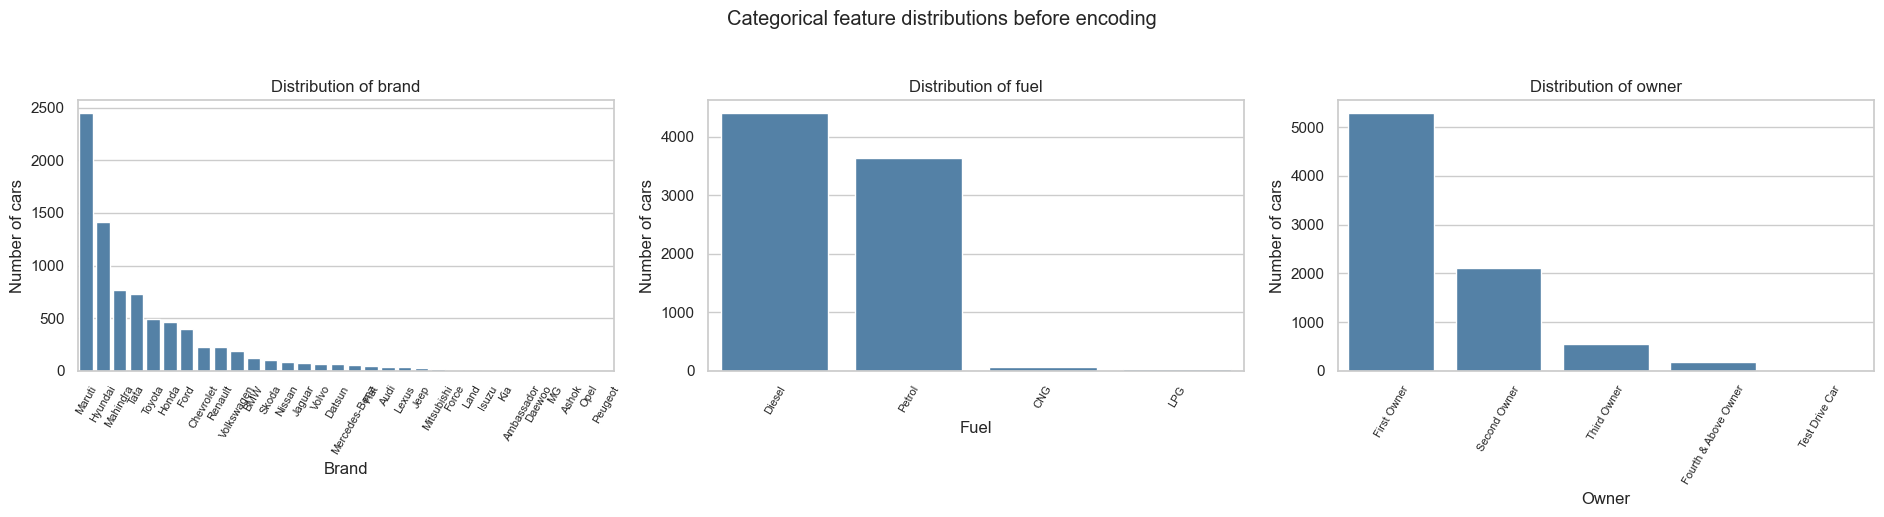

In [5]:
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(19, 5))
for ax, column in zip(axes, categorical_columns):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, color="steelblue", ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of cars")
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
fig.suptitle("Categorical feature distributions before encoding", y=1.03)
fig.tight_layout()
plt.show()

**Interpretation:** the brand distribution is spread over many levels, while fuel and owner are concentrated in a few common categories. In particular, rare brands and “Test Drive Car” have small counts; price summaries for those groups should therefore be treated cautiously. These counts are category frequencies, not ordinal scores.

## 4. Compare price across the original categories

These boxplots use the original labels, not the artificial brand/fuel codes. Price is strongly right-skewed, so the y-axis is logarithmic; hiding fliers keeps the central distributions readable without deleting those observations from the data.

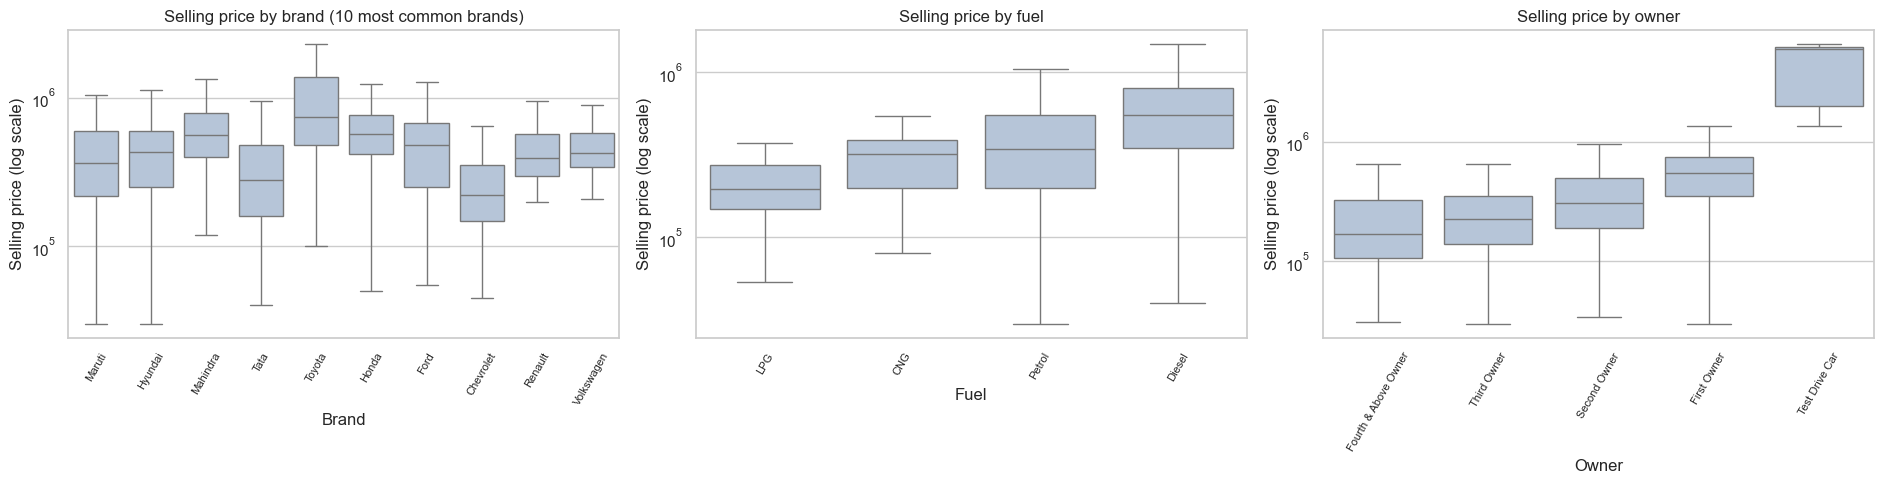

In [6]:
fig, axes = plt.subplots(1, len(categorical_columns), figsize=(19, 5))
for ax, column in zip(axes, categorical_columns):
    if column == "brand":
        order = df[column].value_counts().head(10).index
        plot_df = df[df[column].isin(order)]
        title_suffix = " (10 most common brands)"
    else:
        plot_df = df
        order = df.groupby(column)[target_column].median().sort_values().index
        title_suffix = ""
    sns.boxplot(data=plot_df, x=column, y=target_column, order=order, showfliers=False, color="lightsteelblue", ax=ax)
    ax.set_yscale("log")
    ax.set_title(f"Selling price by {column}{title_suffix}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Selling price (log scale)")
    ax.tick_params(axis="x", labelrotation=60, labelsize=8)
fig.tight_layout()
plt.show()

**Interpretation:** median prices vary across owner and fuel groups, and across the most common brands, suggesting these labels carry useful descriptive information. The boxes overlap, so none of these categories alone determines price. The brand plot includes only the ten most frequent brands for readability; it is not a filtered analysis of the full dataset beyond that figure.

## 5. Visualize the change in predictor dimensionality

Ordinal encoding allocates one numeric feature per source category column. The numeric `km_driven` predictor is kept unchanged, and `selling_price` remains the target.

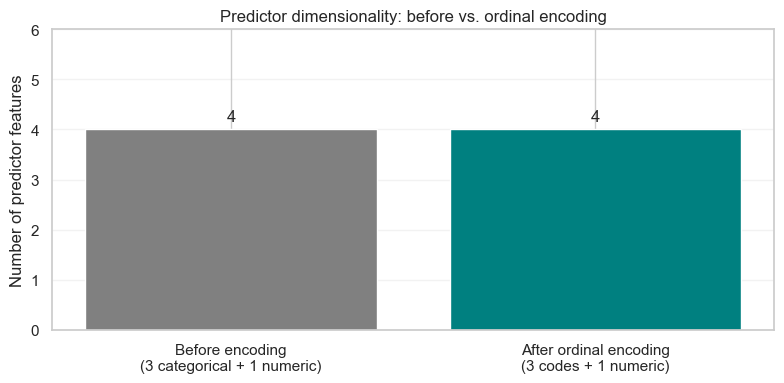

In [7]:
counts = [original_predictor_count, encoded_predictor_count]
labels = ["Before encoding\n(3 categorical + 1 numeric)", "After ordinal encoding\n(3 codes + 1 numeric)"]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, counts, color=["gray", "teal"])
ax.bar_label(bars, padding=4)
ax.set_ylabel("Number of predictor features")
ax.set_title("Predictor dimensionality: before vs. ordinal encoding")
ax.set_ylim(0, max(counts) + 2)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** the predictor count remains four: three categorical columns become three integer-coded columns, and `km_driven` remains numeric. A stable feature count is an advantage, but the compact representation can falsely suggest distances and rankings between nominal labels.

## 6. Correlation heatmap of encoded features

The heatmap below includes the three ordinal-encoded categorical features. It is useful as a numerical diagnostic, but its interpretation is limited: brand and fuel codes were assigned alphabetically, so their Pearson correlations do **not** represent meaningful brand/fuel relationships. Even the owner code summarizes an ordered category, not a continuous measurement.

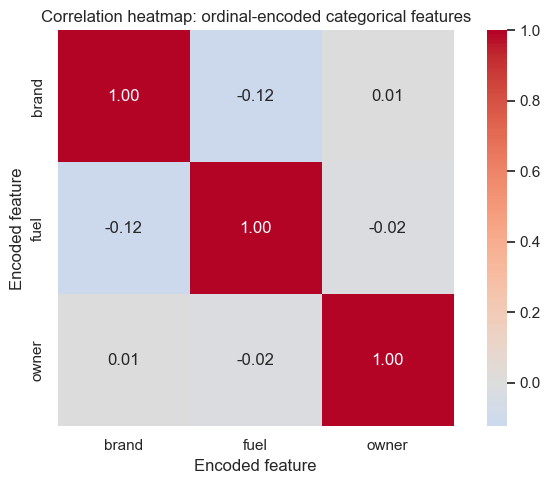

In [8]:
ordinal_correlations = encoded_df.corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(ordinal_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation heatmap: ordinal-encoded categorical features")
ax.set_xlabel("Encoded feature")
ax.set_ylabel("Encoded feature")
plt.tight_layout()
plt.show()

**Interpretation:** correlations involving `brand` or `fuel` mostly reflect the alphabetical code assignment, not an actual ordering. Do not use this heatmap to claim that one brand or fuel type is “higher” than another. For nominal features, one-hot indicators or model-based effect analyses are more appropriate.

## 7. Conclusion: when is ordinal encoding appropriate here?

**Strengths:** compact representation, no increase in predictor count, and a meaningful ordered scale for owner counts from First Owner through Fourth & Above Owner.

**Weaknesses:** numeric codes imply an order and spacing. That implication is artificial for `brand` and `fuel`, and can mislead many models. The special “Test Drive Car” status is not part of the owner-count order, so it needs explicit treatment. Unknown categories also require a policy.

**Recommendation for this dataset:** ordinal encoding is defensible for the ranked owner-count categories (excluding or separately representing the test-drive status). It is not the preferred encoding for `brand` or `fuel` in a model that interprets numeric distances; use one-hot encoding for those nominal columns. If an algorithm handles categorical values natively, consider its categorical-feature support instead. For predictive evaluation, fit the encoder on training folds only and keep preprocessing inside a pipeline.